<a href="https://colab.research.google.com/github/wenh08/Python_projects-/blob/main/USCancerFinalProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# U.S. Cancer Deaths, 2018–2023

**Wenwu Howard | Python final project**

I wanted to see which cancers had the most reported deaths in the U.S. and how the totals differed by race, age, and sex. Race was the main thing I was interested in when I chose this project.


## Research questions

1. Which cancer types had the most reported deaths?
2. Which race had the highest number of reported cancer deaths?
3. Which age groups had the most reported deaths?
4. How did reported cancer deaths differ between males and females?
5. How did reported cancer deaths change from 2018–2023?

I also added a yearly trend test with help from ChatGPT. I explain that help in the inferential statistics section and in the AI assistance note at the end.


## About the dataset

I downloaded this data from CDC WONDER: *United States Cancer Statistics, 2018–2023 Mortality Single race*. The export date is October 26, 2026. [CDC data source](https://wonder.cdc.gov/cancermort-v2022_SR.html).

The original file has **6,717 rows and 12 columns**. It includes **52 rows of notes at the bottom**, so there are **6,665 rows of data** after cleaning. I kept six columns for my analysis. The file covers 22 cancer types, six racial groups, two sexes, and 18 age groups.

Each row contains a death count for a group with a particular year, race, sex, age group, and cancer type. One row can represent many deaths. This is why a file with about 6,000 rows can add up to millions of reported deaths.

**A limit to keep in mind:** this export hides counts below 16 and leaves out zero-count rows. My totals add up the counts that are available in the file, so they do not give the complete U.S. cancer death total. If a group is missing, I cannot assume it had zero deaths. Population sizes and ages also differ between groups, so higher counts alone do not tell me who has a higher cancer risk. This file has no population or state column.


## Loading and checking the data

To run this in Colab, upload `UnitedStatesCancer.csv` using the Files panel. If running it locally, keep the CSV in the same folder as this notebook.

First I'm loading the file and looking at the first and last rows. Then I'm checking the columns, data types, and missing values.


In [ ]:
import pandas as pd
import matplotlib.pyplot as pyp
import seaborn as sns

In [ ]:
# loading my dataset and looking at the first five rows
df = pd.read_csv("UnitedStatesCancer.csv")
display(df.head())


,Notes,Leading Cancer Sites,Leading Cancer Sites Code,Year,Year Code,Age Group,Age Group Code,Sex,Sex Code,Race,Race Code,Deaths
0,NaN,Brain and Other Nervous System,31010-31040,2018.0,2018.0,1-4 years,1-4,Female,F,White,2106-3,20.0
1,NaN,Brain and Other Nervous System,31010-31040,2018.0,2018.0,1-4 years,1-4,Male,M,White,2106-3,29.0
2,NaN,Brain and Other Nervous System,31010-31040,2018.0,2018.0,5-9 years,5-9,Female,F,Black or African American,2054-5,16.0
3,NaN,Brain and Other Nervous System,31010-31040,2018.0,2018.0,5-9 years,5-9,Female,F,White,2106-3,62.0
4,NaN,Brain and Other Nervous System,31010-31040,2018.0,2018.0,5-9 years,5-9,Male,M,White,2106-3,72.0


In [ ]:
# looking at the bottom of the file, where the extra notes are
df.tail(10)


,Notes,Leading Cancer Sites,Leading Cancer Sites Code,Year,Year Code,Age Group,Age Group Code,Sex,Sex Code,Race,Race Code,Deaths
6707,Kaposi Sarcoma deaths included in this dataset are only those deaths with underlying cause of death attributed to Kaposi,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6708,"Sarcoma, and do not include deaths where the condition was a contributing cause of death, or subsequent to another underlying",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6709,"condition. </li><li> The population used to age-adjust the rates in this report is the 2000 U.S. standard population, which is",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6710,in accordance with a 1998 recommendation of the US. Department of Health and Human Services. The 2000 U.S. standard population,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6711,"is based on the proportion of the 2000 population in specific age groups (younger than 1 year, 1-4 years, 5-9 years, 10-14",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6712,"years, 15-19 years, . . . 85 years or older); the proportions of the 2000 population in these age groups serve as weights for",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6713,"calculating age-adjusted incidence and death rates. NCHS, however, uses a different set of age groups in its age adjustment of",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6714,"death rates, and thus the cancer death rates in this report may differ slightly from those published by NCHS. </li><li> Deaths",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6715,of persons of unknown age are not included in this data set. Death rates may differ slightly from other reports where deaths of,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6716,persons of unknown age are included. </li></ul>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# to view the columns and data types and see any missing values
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6717 entries, 0 to 6716
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Notes                      52 non-null     object 
 1   Leading Cancer Sites       6665 non-null   object 
 2   Leading Cancer Sites Code  6665 non-null   object 
 3   Year                       6665 non-null   float64
 4   Year Code                  6665 non-null   float64
 5   Age Group                  6665 non-null   object 
 6   Age Group Code             6665 non-null   object 
 7   Sex                        6665 non-null   object 
 8   Sex Code                   6665 non-null   object 
 9   Race                       6665 non-null   object 
 10  Race Code                  6665 non-null   object 
 11  Deaths                     6665 non-null   float64
dtypes: float64(3), object(9)
memory usage: 629.8+ KB


In [ ]:
# checking for missing values in each column
# Notes has 6,665 missing values. The other columns each have 52.
# those 52 rows contain extra notes at the bottom of this file
df.isna().sum()


,0
Notes,6665
Leading Cancer Sites,52
Leading Cancer Sites Code,52
Year,52
Year Code,52
Age Group,52
Age Group Code,52
Sex,52
Sex Code,52
Race,52


## Cleaning the data

Now I'm dropping the Notes column because I don't need it to answer my questions. Once that column is gone, the 52 rows of notes at the bottom become completely empty, so I remove them too. The original CSV still keeps those notes if I need to refer back to them.


In [ ]:
# dropping Notes because it doesn't answer my research questions
df.drop(columns=['Notes'], errors='ignore', inplace=True)

# removing the empty rows left behind after dropping Notes
df = df.dropna(how='all')


Year and Deaths showed up as decimals. I'm changing them to integers because they should be whole numbers. Then I'm checking for duplicate rows.


In [ ]:
# using .astype() to change Year and Deaths to integers
df = df.astype({'Year': 'int', 'Deaths': 'int'})
df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 6665 entries, 0 to 6664
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Leading Cancer Sites       6665 non-null   object 
 1   Leading Cancer Sites Code  6665 non-null   object 
 2   Year                       6665 non-null   int64  
 3   Year Code                  6665 non-null   float64
 4   Age Group                  6665 non-null   object 
 5   Age Group Code             6665 non-null   object 
 6   Sex                        6665 non-null   object 
 7   Sex Code                   6665 non-null   object 
 8   Race                       6665 non-null   object 
 9   Race Code                  6665 non-null   object 
 10  Deaths                     6665 non-null   int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 624.8+ KB


In [ ]:
# checking for duplicated records
df.duplicated().sum()


np.int64(0)

I'm checking the different values in the columns I'll use. This also helped catch an extra space at the end of `60-64 years `.


In [ ]:
# using .unique() to see the different values in each of these columns
# the loop prints the column name first so I know which values I'm looking at
for column in ['Year', 'Race', 'Sex', 'Age Group', 'Leading Cancer Sites']:
    print(column)
    print(df[column].unique())


Year
[2018 2019 2020 2021 2022 2023]
Race
['White' 'Black or African American' 'Asian' 'More than one race'
 'American Indian or Alaska Native'
 'Native Hawaiian or Other Pacific Islander']
Sex
['Female' 'Male']
Age Group
['1-4 years' '5-9 years' '10-14 years' '15-19 years' '20-24 years'
 '25-29 years' '30-34 years' '35-39 years' '40-44 years' '45-49 years'
 '50-54 years' '55-59 years' '60-64 years ' '65-69 years' '70-74 years'
 '75-79 years' '80-84 years' '85+ years']
Leading Cancer Sites
['Brain and Other Nervous System' 'Breast' 'Cervix Uteri'
 'Colon and Rectum' 'Corpus Uteri' 'Esophagus' 'Gallbladder'
 'Kidney and Renal Pelvis' 'Larynx' 'Leukemias' 'Liver'
 'Lung and Bronchus' 'Melanoma of the Skin' 'Myeloma'
 'Non-Hodgkin Lymphoma' 'Oral Cavity and Pharynx' 'Ovary' 'Pancreas'
 'Prostate' 'Stomach' 'Thyroid' 'Urinary Bladder']


In [ ]:
# removing the extra space at the end of '60-64 years '
# .str.strip() removes spaces from the beginning and end of the age labels
df['Age Group'] = df['Age Group'].str.strip()


Now I'm subsetting to keep only the columns I need for my research questions. I don't need the code columns for these comparisons.


In [ ]:
# subsetting to keep only the columns relevant to my research questions
cancer_df = df[['Year', 'Race', 'Sex', 'Age Group', 'Leading Cancer Sites', 'Deaths']]


## 1. Which cancer types had the most reported deaths?

I'm grouping by cancer type and adding the deaths for each one. This combines the included years, ages, races, and sexes. Then I'm sorting the totals from highest to lowest.


In [ ]:
# adding the reported deaths for each cancer type and sorting highest first
cancer_deaths = cancer_df.groupby('Leading Cancer Sites')['Deaths'].sum().sort_values(ascending=False)
cancer_deaths


,Deaths
Leading Cancer Sites,
Lung and Bronchus,813878
Colon and Rectum,312937
Pancreas,280923
Breast,254969
Prostate,194909
Leukemias,138094
Liver,119084
Non-Hodgkin Lymphoma,118136
Brain and Other Nervous System,103718


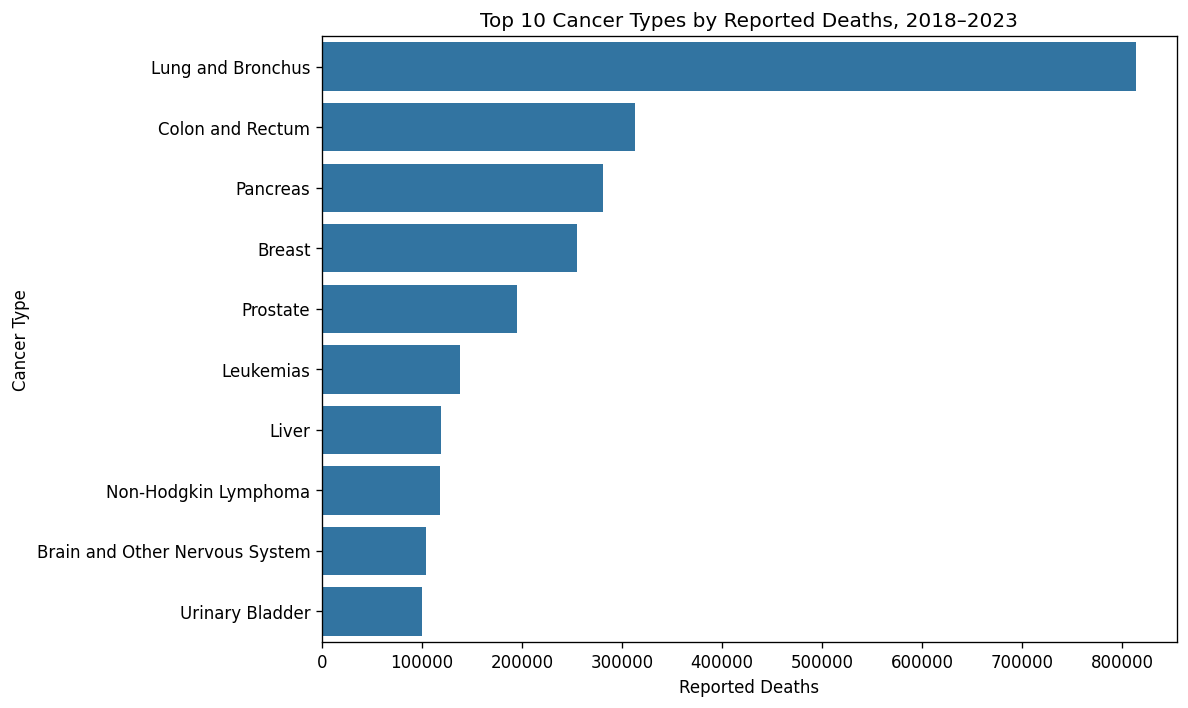

In [ ]:
# now I'm using Seaborn to graph the ten cancers with the most reported deaths
# I chose Seaborn because I find it simpler
top_10 = cancer_deaths.head(10)
pyp.figure(figsize=(10, 6))
sns.barplot(x=top_10.values, y=top_10.index)
pyp.title('Top 10 Cancer Types by Reported Deaths, 2018–2023')
pyp.xlabel('Reported Deaths')
pyp.ylabel('Cancer Type')
pyp.ticklabel_format(style='plain', axis='x')
# keeping the labels from getting cut off
pyp.tight_layout()
pyp.show()


Here we can see that **Lung and Bronchus had the most reported deaths, with 813,878**. Colon and Rectum came next with **312,937**, followed by Pancreas with **280,923**. Thyroid had the lowest total among the included cancer types, with **10,792**. These results compare the death counts available in this file.


## 2. Which race had the highest number of reported cancer deaths?

Now I'm grouping by Race and adding the deaths across the cancer types in this dataset. The graph shows the total for each race from 2018–2023.


In [ ]:
# adding the reported cancer deaths for each race
race_deaths = cancer_df.groupby('Race')['Deaths'].sum()
race_deaths = race_deaths.sort_values(ascending=False)
display(race_deaths)


,Deaths
Race,
White,2587462
Black or African American,359057
Asian,88535
American Indian or Alaska Native,8772
More than one race,7424
Native Hawaiian or Other Pacific Islander,225


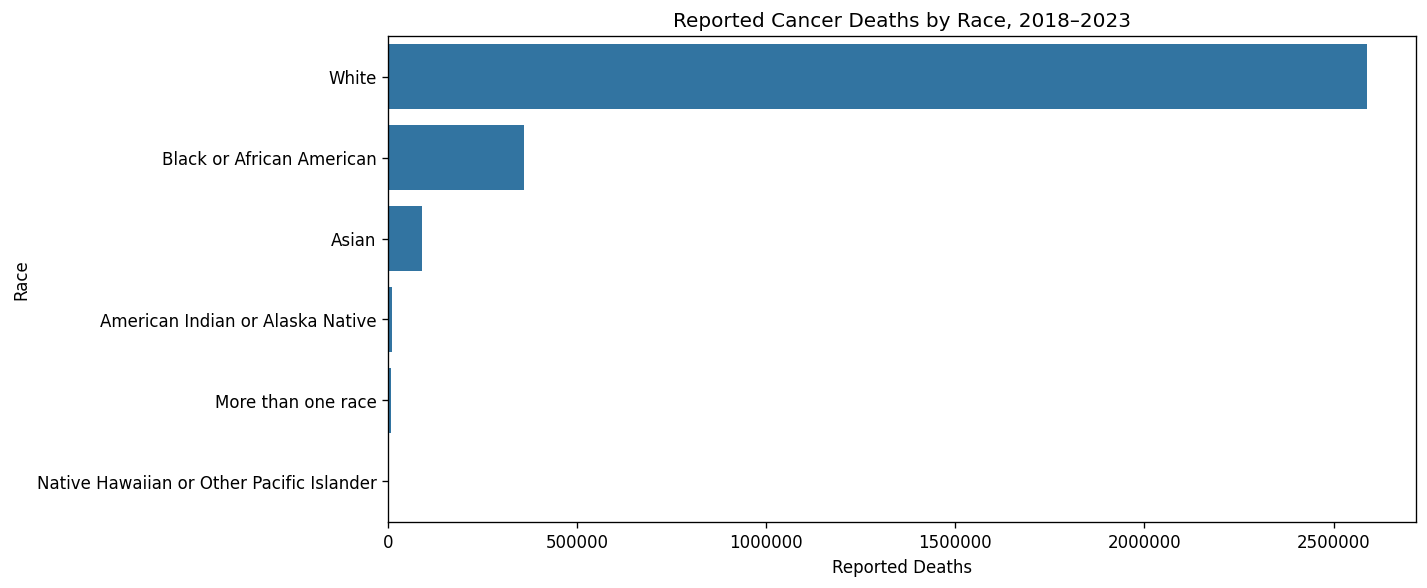

In [ ]:
# bar graph showing the reported cancer death total for each race
pyp.figure(figsize=(12, 5))
sns.barplot(x=race_deaths.values, y=race_deaths.index)
pyp.title('Reported Cancer Deaths by Race, 2018–2023')
pyp.xlabel('Reported Deaths')
pyp.ylabel('Race')
# showing the full numbers on the axis
pyp.ticklabel_format(style='plain', axis='x')
# keeping the labels from getting cut off
pyp.tight_layout()
pyp.show()


Here we can see that **White had the highest reported total, with 2,587,462 deaths**. Black or African American came next with **359,057**.

The file only shows **225 deaths** for Native Hawaiian or Other Pacific Islander. CDC hides small counts, which can leave out a lot of information for smaller groups. I can't use that low visible total to say this group had the lowest cancer risk. Differences in population size and age also matter when comparing these counts.


## 3. Which age groups had the most reported deaths?

I'm grouping by Age Group, adding the deaths, and sorting from highest to lowest. This lets me see which age groups had the largest totals.


In [ ]:
# adding the reported deaths for each age group and sorting highest first
age_deaths = cancer_df.groupby(['Age Group'])['Deaths'].sum().sort_values(ascending=False)
age_deaths


,Deaths
Age Group,
85+ years,514664
70-74 years,475702
75-79 years,457272
65-69 years,424125
80-84 years,389971
60-64 years,340673
55-59 years,212436
50-54 years,111935
45-49 years,58465


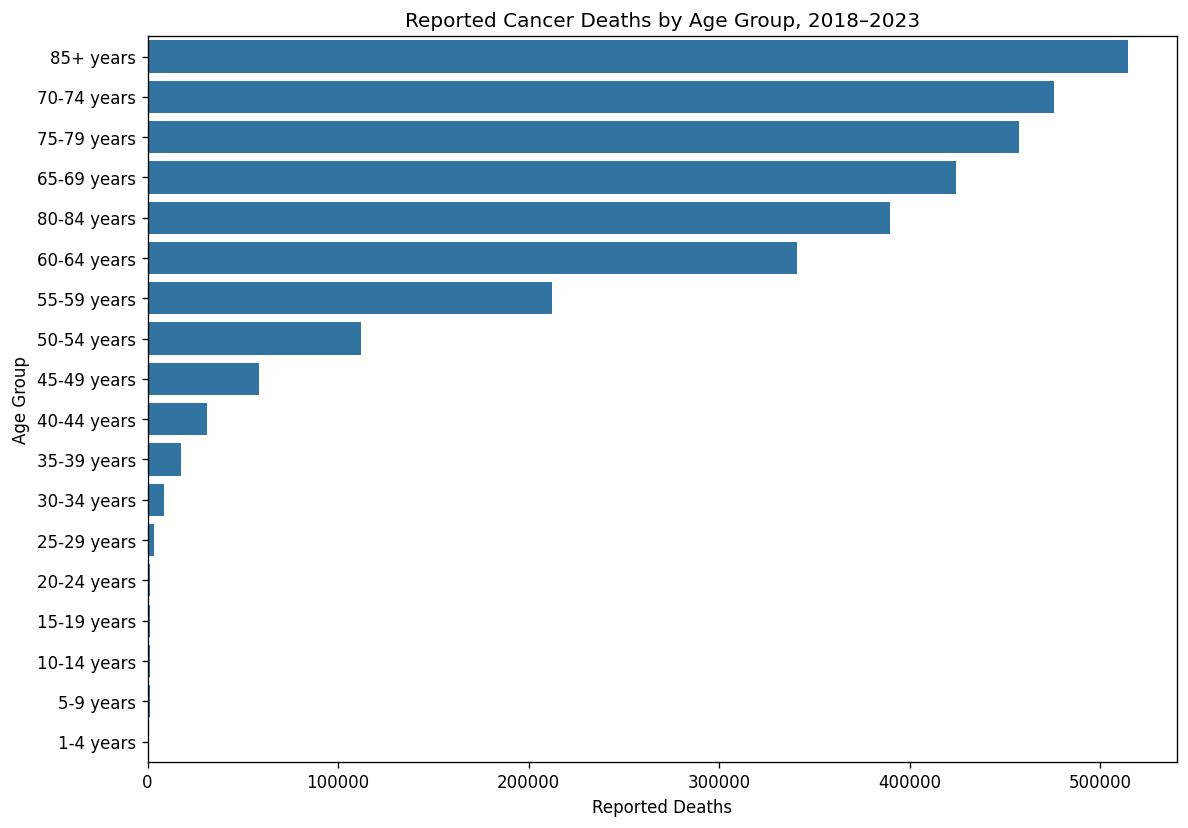

In [ ]:
# bar graph showing the reported deaths for each age group
pyp.figure(figsize=(10, 7))
sns.barplot(x=age_deaths.values, y=age_deaths.index)
pyp.title('Reported Cancer Deaths by Age Group, 2018–2023')
pyp.xlabel('Reported Deaths')
pyp.ylabel('Age Group')
pyp.ticklabel_format(style='plain', axis='x')
# keeping the labels from getting cut off
pyp.tight_layout()
pyp.show()


Here we can see that **ages 85+ had the most reported deaths, with 514,664**. Ages **1–4 had the lowest total, with 644**.

The 85+ group includes everyone above that age, while the other adult groups cover five years each. The totals also depend on how many people are in each group.


## 4. How did reported cancer deaths differ between males and females?

Now I'm grouping by Sex and adding the deaths. I kept my variable name `cancer_by_gender`, but the column in the dataset is called `Sex`.


In [ ]:
# adding the reported cancer deaths for males and females
cancer_by_gender = cancer_df.groupby('Sex')['Deaths'].sum().sort_values(ascending=False)
cancer_by_gender


,Deaths
Sex,
Male,1622025
Female,1429450


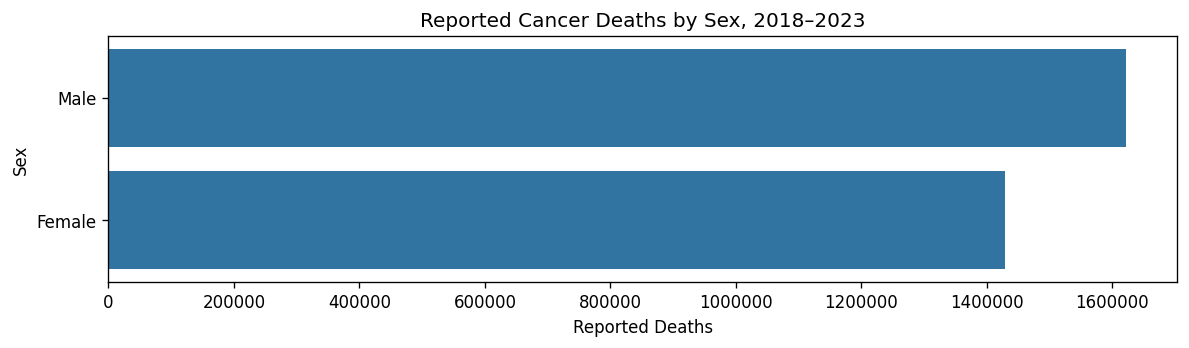

In [ ]:
# bar graph showing the reported cancer deaths for males and females
pyp.figure(figsize=(10, 3))
sns.barplot(x=cancer_by_gender.values, y=cancer_by_gender.index)
pyp.title('Reported Cancer Deaths by Sex, 2018–2023')
pyp.xlabel('Reported Deaths')
pyp.ylabel('Sex')
# showing the full numbers on the axis
pyp.ticklabel_format(style='plain', axis='x')
# keeping the labels from getting cut off
pyp.tight_layout()
pyp.show()


Here we can see that **males had 1,622,025 reported deaths** and **females had 1,429,450**. That is **192,575 more reported deaths among males** in this dataset. To compare the death rates, I would also need the population sizes and ages of these groups.


## 5. How did reported cancer deaths change from 2018–2023?

I'm adding the deaths for each year. I keep the years in order so the line graph is easy to follow.


In [ ]:
# adding the reported deaths for each year
# keeping the years in order for the line graph
year_deaths = cancer_df.groupby('Year')['Deaths'].sum()
display(year_deaths)


,Deaths
Year,
2018,508412
2019,507469
2020,508230
2021,507959
2022,508184
2023,511221


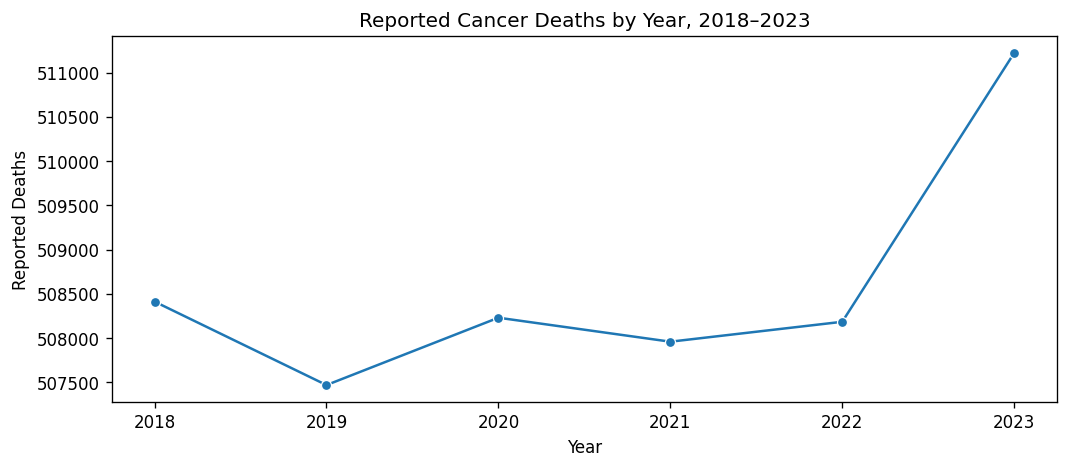

In [ ]:
# using a line graph to see how the yearly totals changed from 2018 to 2023
pyp.figure(figsize=(9, 4))
sns.lineplot(x=year_deaths.index, y=year_deaths.values, marker='o')
pyp.title('Reported Cancer Deaths by Year, 2018–2023')
pyp.xlabel('Year')
pyp.ylabel('Reported Deaths')
pyp.ticklabel_format(style='plain', axis='y')
# keeping the labels from getting cut off
pyp.tight_layout()
pyp.show()


Here we can see that **2023 had the highest reported total, with 511,221 deaths**, and **2019 had the lowest, with 507,469**. In 2018, the total was **508,412**. From 2018 to 2023, the count went up by **2,809 deaths, or about 0.55%**.

The graph's vertical axis starts near 507,000 to make the small changes easier to see. That makes the rise look larger on the graph, even though the overall percentage change is small.


## Descriptive statistics

I'm using `.describe()` to look at the mean, median, spread, and quartiles of the yearly totals. The `count` below is six because there are six years. The `50%` value is the median.


In [ ]:
# looking at the descriptive statistics for the six yearly totals
year_deaths.describe()


,Deaths
count,6.000000
mean,508579.166667
std,1334.344696
min,507469.000000
25%,508015.250000
50%,508207.000000
75%,508366.500000
max,511221.000000


## Inferential statistics: looking for a yearly trend

**I needed extra help from ChatGPT with this section (OpenAI, 2026).** ChatGPT suggested linear regression, wrote the code below, and helped explain how to interpret the results.

This method fits a straight line to the yearly totals. The slope tells us whether that fitted line goes up or down and by how much each year. The test looks for evidence of a steady increase or decrease across all six years.

- **Null hypothesis:** the slope is zero, meaning no linear trend.
- **Alternative hypothesis:** the slope is positive or negative.
- **Significance level:** 0.05. This is the cutoff used to evaluate the p-value.

The t-value divides the estimated slope by its standard error. The standard error measures uncertainty in the slope estimate. The 95% confidence interval gives a range for the slope based on the model.

This test uses **six numbers, one total for each year**. For the test to be reliable, the gaps between the yearly totals and the fitted line need to be independent, roughly normally distributed, and have a similar spread across years. It also assumes a straight-line average trend. With only six years, I can't check these assumptions well. Changes in population and hidden counts can also affect the totals, so I treat this as an exploratory classroom analysis.

Method references: [SciPy linregress](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.linregress.html) and [NIST regression assumptions](https://www.itl.nist.gov/div898/handbook/pri/section2/pri245.htm).


In [ ]:
# ChatGPT suggested this method and wrote this code (OpenAI, 2026)
from scipy.stats import linregress, t

# fitting a straight line using the years and their reported death totals
trend = linregress(year_deaths.index, year_deaths.values)

# dividing the slope by its standard error to get the t-value
t_value = trend.slope / trend.stderr

# there are six yearly totals, and the line estimates a slope and an intercept
degrees_of_freedom = len(year_deaths) - 2

# 0.975 leaves 2.5% in each end for a two-sided 95% confidence interval
critical_t = t.ppf(0.975, degrees_of_freedom)

# finding the lower and upper ends of the confidence interval for the slope
ci_lower = trend.slope - critical_t * trend.stderr
ci_upper = trend.slope + critical_t * trend.stderr

print('Years used:', len(year_deaths))
print('Estimated annual change:', round(trend.slope, 2))
print('t-value:', round(t_value, 3))
print('Two-sided p-value:', round(trend.pvalue, 4))
print('95% CI for slope:', round(ci_lower, 2), 'to', round(ci_upper, 2))


Years used: 6
Estimated annual change: 454.83
t-value: 1.656
Two-sided p-value: 0.1731
95% CI for slope: -307.86 to 1217.52


The fitted line estimates an increase of about **455 reported deaths per year**. The t-value is **1.66**, and the p-value is **0.173**. Since 0.173 is higher than the 0.05 cutoff, this test does not give enough evidence of a steady linear trend. In hypothesis-testing terms, I fail to reject the null hypothesis under this model.

The **95% confidence interval for the slope runs from about −308 to +1,218 reported deaths per year**. It includes zero and covers both a decrease and an increase. That also leaves the direction of the trend uncertain. The actual totals still went up by 0.55% between 2018 and 2023. The test does not prove that nothing changed, and the p-value does not tell us the probability that the null hypothesis is true.

ChatGPT helped draft and explain this interpretation (OpenAI, 2026). The result depends on the test's assumptions and only six years of data.


## Conclusion

Lung and Bronchus had the most reported deaths among the cancer types in this dataset. White had the largest reported total by race, ages 85+ had the largest total by age group, and males had more reported deaths than females.

The yearly totals changed only a little from 2018–2023. The 2023 total was about 0.55% higher than the 2018 total. With help from ChatGPT, I also used a regression test. That test did not find enough evidence of a steady linear trend at the 0.05 cutoff.

These findings describe the counts available in my file. CDC hides small counts, and the groups have different population sizes and ages. To compare cancer risk, I would need population data and age-adjusted mortality rates. More years of data would also help when looking at the trend over time.


## AI assistance

I used ChatGPT (OpenAI, 2026) for help with Python code, explanations, notebook organization, and drafting my presentation. I understand the data cleaning, grouping, and descriptive analysis. I needed additional help with inferential statistics. ChatGPT suggested the linear regression method, wrote the code for that section, and helped explain the results, including the slope, p-value, and confidence interval.


## References

- CDC WONDER. *United States Cancer Statistics, 2018–2023 Mortality Single race.* Exported October 26, 2026. https://wonder.cdc.gov/cancermort-v2022_SR.html
- CDC WONDER. USCS mortality documentation and suppression rules. https://wonder.cdc.gov/wonder/help/cancermort-v2023.html
- SciPy. `scipy.stats.linregress`. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.linregress.html
- NIST/SEMATECH. Check of regression assumptions. https://www.itl.nist.gov/div898/handbook/pri/section2/pri245.htm
- American Statistical Association. Statement on statistical significance and p-values. https://www.amstat.org/asa/files/pdfs/P-ValueStatement.pdf
- OpenAI. (2026). *ChatGPT* [Large language model]. https://chatgpt.com/
